# Explore the AequilibraE example projects

This notebook opens the two projects in `ae-projects/`:

* **hearn-example**: the 4-node Braess network
* **sioux-falls**: Sioux Falls imported from `gmns-data/17_Sioux_Falls`

Create them first from the repository root:

```bash
uv run --overwrite create-ae-projects
```

In [1]:
!pwd

/Users/sagar/Documents/GitHub/fair-tolling/experiments


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from aequilibrae import Project

# Find the AE Projects root 
AE_DIR = Path("../ae-projects").resolve()
sorted(p.name for p in AE_DIR.iterdir() if p.is_dir())

['hearn-example', 'sioux-falls']

In [3]:
def plot_network(project, title, label_nodes=True):
    links = project.network.links.data
    nodes = project.network.nodes.data
    ax = links.plot(color="steelblue", linewidth=1.5, figsize=(6, 6))
    nodes.plot(ax=ax, color="black", markersize=20, zorder=3)
    if label_nodes:
        for _, row in nodes.iterrows():
            ax.annotate(str(row.node_id), (row.geometry.x, row.geometry.y),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.set_title(title)
    ax.set_axis_off()
    return ax


def demand_frame(project, matrix_name, core="volume"):
    mat = project.matrices.get_matrix(matrix_name)
    index = mat.index.flatten() if hasattr(mat.index, "flatten") else mat.index
    df = pd.DataFrame(mat.get_matrix(core), index=index, columns=index)
    mat.close()
    return df

## 1. hearn-example (Braess network)

Link cost uses BPR, `t = t0 * (1 + alpha * (v / capacity) ** beta)`, with the parameters stored as link fields `free_flow_time`, `alpha` and `beta`.

In [4]:
hearn = Project()
hearn.open(str(AE_DIR / "hearn-example"))

print("links:", len(hearn.network.links.data), "| nodes:", len(hearn.network.nodes.data))
print("modes:", {k: v.mode_name for k, v in hearn.network.modes.all_modes().items()})

links: 5 | nodes: 4
modes: {'b': 'bicycle', 'c': 'car', 't': 'transit', 'w': 'walk'}


In [5]:
hearn.network.links.data[["link_id", "a_node", "b_node", "direction", "modes",
                          "capacity_ab", "free_flow_time", "alpha", "beta"]]

,link_id,a_node,b_node,direction,modes,capacity_ab,free_flow_time,alpha,beta
0,1,2,1,1,c,4000,1.00,40,1
1,2,2,3,1,c,4000,45.00,0,1
2,3,1,4,1,c,4000,45.00,0,1
3,4,3,4,1,c,4000,1.00,40,1
4,5,1,3,1,c,4000,0.01,0,1


In [6]:
hearn.network.nodes.data[["node_id", "is_centroid", "modes", "geometry"]]

,node_id,is_centroid,modes,geometry
0,1,1,c,POINT (0.01 0.01)
1,2,0,c,POINT (0 0)
2,3,0,c,POINT (0.01 -0.01)
3,4,1,c,POINT (0.02 0)


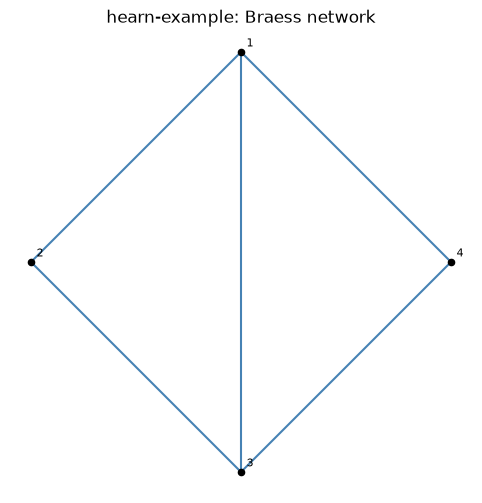

In [7]:
plot_network(hearn, "hearn-example: Braess network");

### Demand

In [8]:
print(hearn.matrices.list()[["name", "file_name", "cores"]])
demand_frame(hearn, "braess_demand")

            name          file_name  cores
0  braess_demand  braess_demand.omx      1


,1,4
1,0.0,4000.0
4,0.0,0.0


### Shortest path on free-flow time

Nodes 1 and 4 are centroids, so we can build the car graph and query a path.

In [9]:
hearn.network.build_graphs(modes=["c"])
g = hearn.network.graphs["c"]
g.set_graph("free_flow_time")
g.set_skimming(["free_flow_time"])
g.set_blocked_centroid_flows(False)

res = g.compute_path(1, 4)
print("nodes:", res.path_nodes)
print("links:", res.path)
print("free-flow time:", res.milepost[-1])

nodes: [1 3 4]
links: [5 4]
free-flow time: 1.01


In [10]:
hearn.close()

## 2. sioux-falls (from GMNS)

Imported with `create_from_gmns`. The BPR parameters from the GMNS file are kept as link fields `vdf_fftt`, `vdf_alpha` and `vdf_beta`.

In [20]:
sf = Project()
sf.open(str(AE_DIR / "sioux-falls"))

sf_links = sf.network.links.data
sf_nodes = sf.network.nodes.data
print("links:", len(sf_links), "| nodes:", len(sf_nodes),
      "| centroids:", int(sf_nodes.is_centroid.sum()))
print("modes:", {k: v.mode_name for k, v in sf.network.modes.all_modes().items()})
print("link types:", sorted(sf_links.link_type.unique()))

links: 38 | nodes: 24 | centroids: 24
modes: {'b': 'bicycle', 'c': 'car', 't': 'transit', 'w': 'walk'}
link types: ['unclassified']


In [21]:
sf_links[["link_id", "a_node", "b_node", "direction", "modes", "distance",
          "capacity_ab", "speed_ab", "vdf_fftt", "vdf_alpha", "vdf_beta"]].head(10)

,link_id,a_node,b_node,direction,modes,distance,capacity_ab,speed_ab,vdf_fftt,vdf_alpha,vdf_beta
0,1,1,2,0,c,4898.585873,25900.200640,96.54,6,0.15,4
1,2,1,3,0,c,4483.412863,23403.473190,96.54,4,0.15,4
2,4,2,6,0,c,2068.233630,4958.180928,96.54,5,0.15,4
3,6,3,4,0,c,2481.192455,17110.523720,96.54,4,0.15,4
4,7,3,12,0,c,3302.105484,23403.473190,96.54,4,0.15,4
5,9,4,5,0,c,1319.781389,17782.794100,96.54,2,0.15,4
6,10,4,11,0,c,2211.983103,4908.826730,96.54,6,0.15,4
7,12,5,6,0,c,3122.063100,4947.995469,96.54,4,0.15,4
8,13,5,9,0,c,1758.115542,10000.000000,96.54,5,0.15,4
9,16,6,8,0,c,2849.635653,4898.587646,96.54,2,0.15,4


In [22]:
sf_links[["capacity_ab", "vdf_fftt", "vdf_alpha", "vdf_beta", "distance"]].describe()

,capacity_ab,vdf_fftt,vdf_alpha,vdf_beta,distance
count,38.000000,38.000000,3.800000e+01,38.0,38.000000
mean,10247.206327,4.131579,1.500000e-01,4.0,2146.916284
std,7408.208841,1.742490,5.625630e-17,0.0,1182.913520
min,4823.950831,2.000000,1.500000e-01,4.0,412.623819
25%,4967.013369,3.000000,1.500000e-01,4.0,1629.699107
50%,5109.391136,4.000000,1.500000e-01,4.0,1739.452198
75%,14402.511968,5.000000,1.500000e-01,4.0,2427.924563
max,25900.200640,10.000000,1.500000e-01,4.0,6054.527814


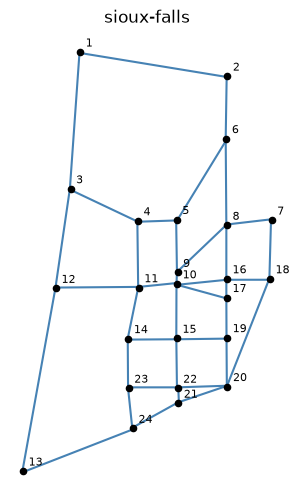

In [23]:
plot_network(sf, "sioux-falls");

### Demand

In [24]:
print(sf.matrices.list()[["name", "file_name", "cores"]])
sf_demand = demand_frame(sf, "sioux_falls_demand")
print("total trips:", sf_demand.to_numpy().sum())
sf_demand.iloc[:8, :8]

                 name               file_name  cores
0  sioux_falls_demand  sioux_falls_demand.omx      1
total trips: 360600.0


,1,2,3,4,5,6,7,8
1,0.0,100.0,100.0,500.0,200.0,300.0,500.0,800.0
2,100.0,0.0,100.0,200.0,100.0,400.0,200.0,400.0
3,100.0,100.0,0.0,200.0,100.0,300.0,100.0,200.0
4,500.0,200.0,200.0,0.0,500.0,400.0,400.0,700.0
5,200.0,100.0,100.0,500.0,0.0,200.0,200.0,500.0
6,300.0,400.0,300.0,400.0,200.0,0.0,400.0,800.0
7,500.0,200.0,100.0,400.0,200.0,400.0,0.0,1000.0
8,800.0,400.0,200.0,700.0,500.0,800.0,1000.0,0.0


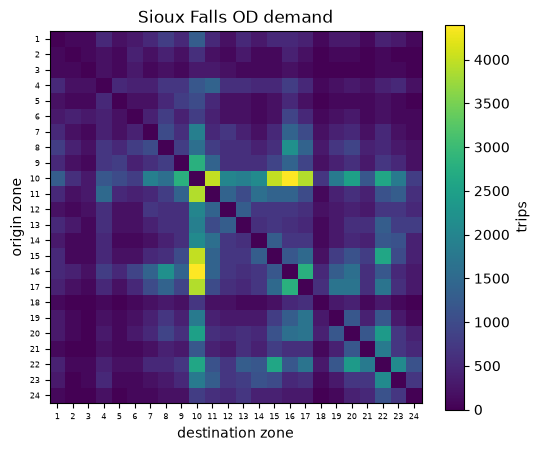

In [25]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sf_demand.to_numpy(), cmap="viridis")
ax.set_xticks(range(len(sf_demand.columns)), sf_demand.columns, fontsize=6)
ax.set_yticks(range(len(sf_demand.index)), sf_demand.index, fontsize=6)
ax.set_xlabel("destination zone")
ax.set_ylabel("origin zone")
ax.set_title("Sioux Falls OD demand")
fig.colorbar(im, ax=ax, label="trips");

### Shortest path on free-flow time

In [26]:
sf.network.build_graphs(modes=["c"])
g = sf.network.graphs["c"]
g.set_graph("vdf_fftt")
g.set_skimming(["vdf_fftt", "distance"])
g.set_blocked_centroid_flows(False)  # every node is a centroid in Sioux Falls

res = g.compute_path(1, 20)
print("nodes:", res.path_nodes)
print("links:", res.path)
print("free-flow time:", res.milepost[-1])

nodes: [ 1  2  6  8  7 18 20]
links: [ 1  4 16 17 18 56]
free-flow time: 22.0


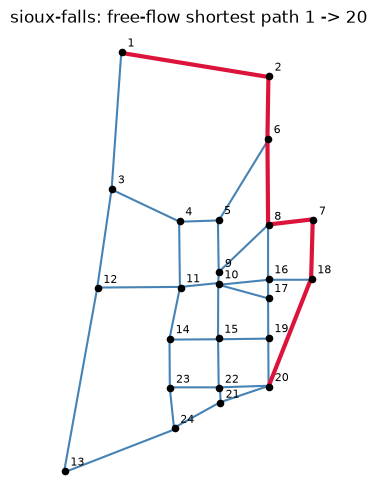

In [27]:
ax = plot_network(sf, "sioux-falls: free-flow shortest path 1 -> 20")
sf_links[sf_links.link_id.isin(res.path)].plot(ax=ax, color="crimson", linewidth=3);

In [28]:
sf.close()